In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
analytics_auto = pd.read_csv(r'C:\Users\JUAN\Documents\GitHub\Analytic-Auto-Imports\Automobile_data.csv')
analytics_auto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num-of-doors       205 non-null    object 
 6   body-style         205 non-null    object 
 7   drive-wheels       205 non-null    object 
 8   engine-location    205 non-null    object 
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    object 
 15  num-of-cylinders   205 non-null    object 
 16  engine-size        205 non

In [3]:
analytics_auto['price'].unique()
(analytics_auto['price'] == '?').sum()

np.int64(4)

In [4]:
columnas_sospechosas = ['normalized-losses', 'bore', 'stroke', 'horsepower', 'peak-rpm', 'price']
for col in columnas_sospechosas:
    print(col, (analytics_auto[col] == '?').sum())

normalized-losses 41
bore 4
stroke 4
horsepower 2
peak-rpm 2
price 4


In [5]:
for col in columnas_sospechosas:
    analytics_auto[col] = pd.to_numeric(analytics_auto[col], errors='coerce')
analytics_auto[columnas_sospechosas].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   normalized-losses  164 non-null    float64
 1   bore               201 non-null    float64
 2   stroke             201 non-null    float64
 3   horsepower         203 non-null    float64
 4   peak-rpm           203 non-null    float64
 5   price              201 non-null    float64
dtypes: float64(6)
memory usage: 9.7 KB


In [6]:
analytics_auto['price'] = analytics_auto['price'].fillna(analytics_auto['price'].median())
analytics_auto['normalized-losses'] = analytics_auto['normalized-losses'].fillna(
    analytics_auto.groupby('body-style')['normalized-losses'].transform('median')
)
analytics_auto[['price', 'normalized-losses']].isnull().sum()

price                0
normalized-losses    0
dtype: int64

In [7]:
columnas_restantes = ['bore', 'stroke', 'horsepower', 'peak-rpm']
for col in columnas_restantes:
    analytics_auto[col] = analytics_auto[col].fillna(analytics_auto[col].median())
analytics_auto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    float64
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num-of-doors       205 non-null    object 
 6   body-style         205 non-null    object 
 7   drive-wheels       205 non-null    object 
 8   engine-location    205 non-null    object 
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    object 
 15  num-of-cylinders   205 non-null    object 
 16  engine-size        205 non

In [8]:
#correlacion horsepower y power 
analytics_auto['horsepower'].corr(analytics_auto['price'])


np.float64(0.7499191229023523)

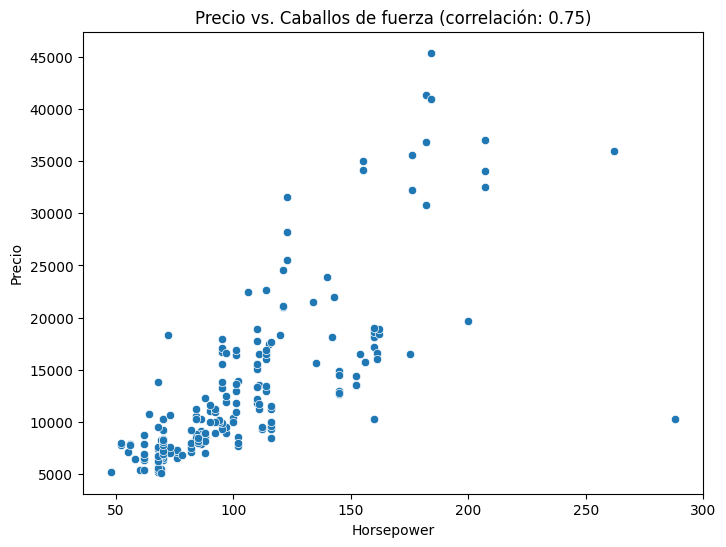

In [9]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=analytics_auto, x='horsepower', y='price')
plt.title(f'Precio vs. Caballos de fuerza (correlación: 0.75)')
plt.xlabel('Horsepower')
plt.ylabel('Precio')
plt.show()

In [10]:
analytics_auto[analytics_auto['horsepower'] > 250][['make', 'horsepower', 'price', 'body-style']]

,make,horsepower,price,body-style
49,jaguar,262.0,36000.0,sedan
129,porsche,288.0,10295.0,hatchback


In [11]:
auto_sin_outlier = analytics_auto[analytics_auto['price'] != 10295].copy()

In [12]:
auto_sin_outlier['horsepower'].corr(auto_sin_outlier['price'])

np.float64(0.8103573608816755)

In [13]:
columnas_numericas = ['price', 'horsepower', 'engine-size', 'curb-weight', 'city-mpg', 'highway-mpg', 'wheel-base', 'length', 'width']
matriz_corr = auto_sin_outlier[columnas_numericas].corr()
matriz_corr

,price,horsepower,engine-size,curb-weight,city-mpg,highway-mpg,wheel-base,length,width
price,1.000000,0.810357,0.872243,0.834306,-0.686419,-0.704509,0.584352,0.691057,0.753488
horsepower,0.810357,1.000000,0.822005,0.757783,-0.821119,-0.804366,0.371609,0.579236,0.614751
engine-size,0.872243,0.822005,1.000000,0.848968,-0.650368,-0.679357,0.571697,0.685524,0.731239
curb-weight,0.834306,0.757783,0.848968,1.000000,-0.749426,-0.794765,0.781951,0.881138,0.869297
city-mpg,-0.686419,-0.821119,-0.650368,-0.749426,1.000000,0.972038,-0.470331,-0.665481,-0.635527
highway-mpg,-0.704509,-0.804366,-0.679357,-0.794765,0.972038,1.000000,-0.543011,-0.698527,-0.682556
wheel-base,0.584352,0.371609,0.571697,0.781951,-0.470331,-0.543011,1.000000,0.876546,0.817087
length,0.691057,0.579236,0.685524,0.881138,-0.665481,-0.698527,0.876546,1.000000,0.863641
width,0.753488,0.614751,0.731239,0.869297,-0.635527,-0.682556,0.817087,0.863641,1.000000


In [14]:
plt.figure(figsize=(10, 7))
sns.heatmap(    , annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Matriz de correlación: variables técnicas vs. precio')
plt.show()

SyntaxError: invalid syntax (2302736596.py, line 2)

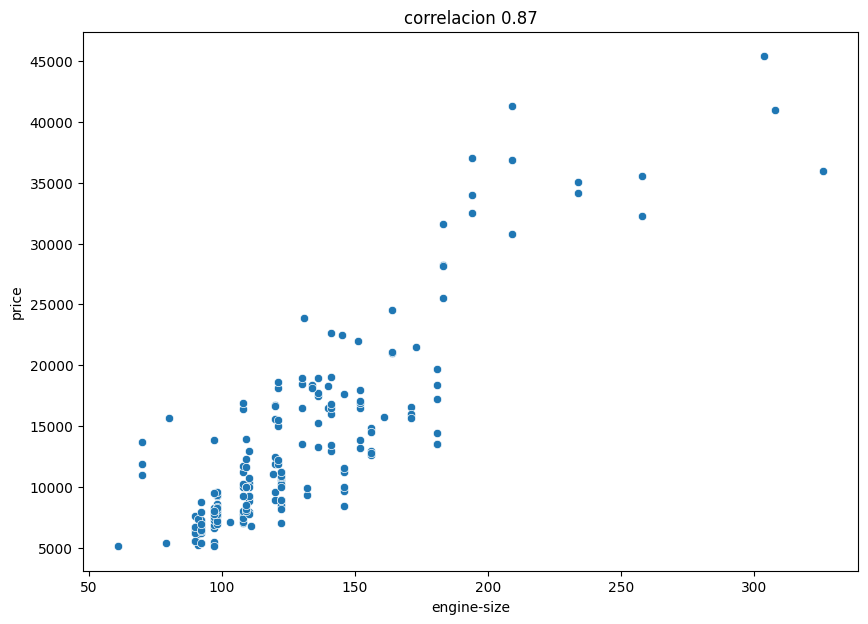

In [ ]:
plt.figure(figsize=(10,7))
sns.scatterplot(data=auto_sin_outlier, x='engine-size', y='price')
plt.title('correlacion 0.87')
plt.show()

In [ ]:
group_cars = auto_sin_outlier.groupby('make')['price'].mean().sort_values(ascending=False)
group_cars.head()

make
jaguar           34600.000000
mercedes-benz    33647.000000
porsche          31400.500000
bmw              26118.750000
volvo            18063.181818
Name: price, dtype: float64

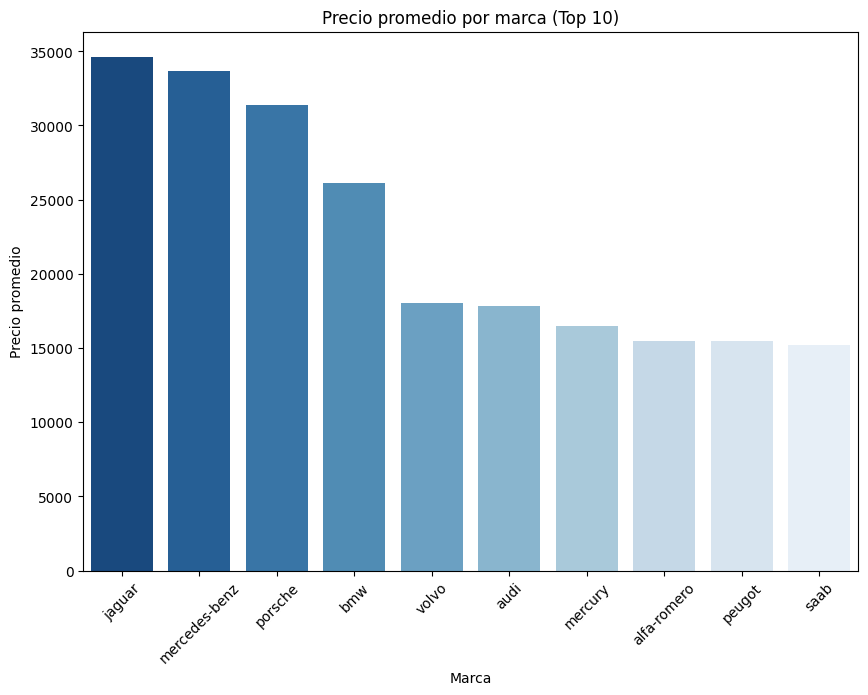

In [ ]:
plt.figure(figsize=(10, 7))
sns.barplot(x=group_cars.head(10).index, y=group_cars.head(10).values, hue=group_cars.head(10).index, palette='Blues_r', legend=False)
plt.title('Precio promedio por marca (Top 10)')
plt.xlabel('Marca')
plt.ylabel('Precio promedio')
plt.xticks(rotation=45)
plt.show()

In [15]:
auto_sin_outlier[auto_sin_outlier['make'] == 'romero']
auto_sin_outlier[auto_sin_outlier['make'].str.contains('romero')]

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,138.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,138.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,129.0,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0


In [16]:
group_body = auto_sin_outlier.groupby('body-style')['price'].mean().sort_values(ascending=False)
group_body

body-style
hardtop        22208.500000
convertible    21890.500000
sedan          14504.537634
wagon          12371.960000
hatchback       9957.441176
Name: price, dtype: float64

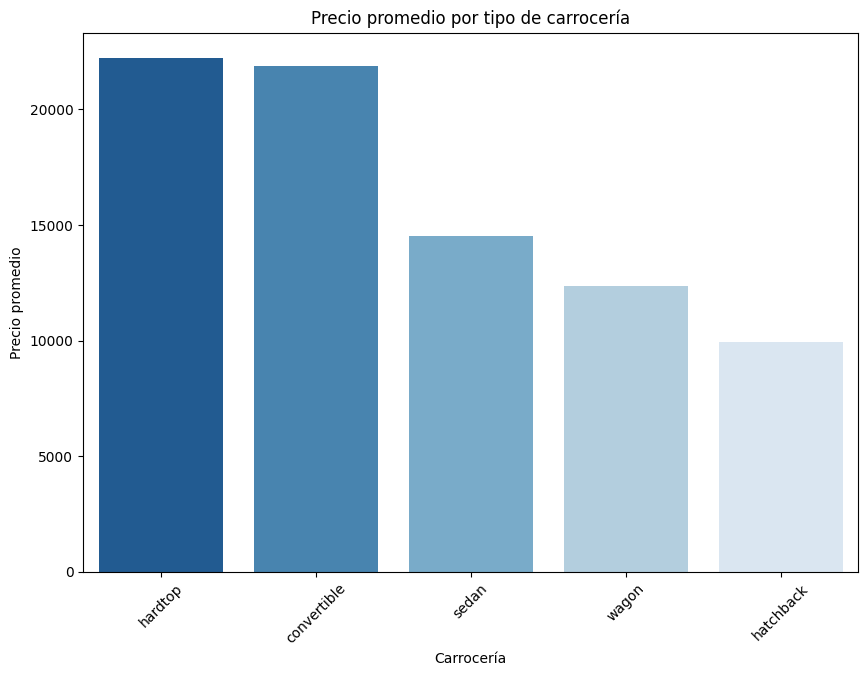

In [18]:
plt.figure(figsize=(10, 7))
sns.barplot(x=group_body.head(10).index, y=group_body.head(10).values, hue=group_body.head(10).index, palette='Blues_r', legend=False)
plt.title('Precio promedio por tipo de carrocería')
plt.xlabel('Carrocería')
plt.ylabel('Precio promedio')
plt.xticks(rotation=45)
plt.show()